# Task 1: من Matplotlib إلى Seaborn
مقدمة المهمة

# في هذه المهمة سنتعرف على مكتبة Seaborn والفرق بينها وبين Matplotlib، ونتعلم كيف نستخدم الرسوم البيانية لفهم البيانات وتحليلها.

# السؤال الأول: الفرق بين Matplotlib وSeaborn

Matplotlib مكتبة نستخدمها لإنشاء الرسوم البيانية والتحكم في تفاصيلها بشكل كبير.

أما Seaborn فهي مبنية على Matplotlib، وتوفر طريقة أسهل وأسرع لإنشاء رسوم بيانية جميلة وتساعد في تحليل البيانات.

نتعلم الاثنين لأن Matplotlib تعطينا تحكمًا أكبر في الرسومات، بينما Seaborn تسهّل علينا عرض البيانات وفهم العلاقات بينها.

# السؤال الثاني: وظيفة hue

تُستخدم `hue` لتلوين البيانات حسب فئة معينة، حتى نستطيع التمييز بين المجموعات ومقارنة النتائج بسهولة.

مثال من بيانات القروض التي عملت عليها: أستخدم `hue="Loan_Status"` لتلوين طلبات القروض حسب حالة الموافقة أو الرفض.

سيساعدني ذلك على اكتشاف الاختلافات بين الطلبات المقبولة والمرفوضة، وفهم توزيع البيانات لكل مجموعة.

# السؤال الثالث: الخط الأسود في Barplot

الخط الأسود الصغير يمثل فترة الثقة (Confidence Interval)، ويوضح مدى عدم التأكد حول متوسط القيمة في كل مجموعة.

أهميته أنه يساعدنا على معرفة مدى دقة المقارنة بين الأعمدة، فإذا كانت فترات الثقة متداخلة فلا نستطيع الجزم بسهولة أن الفرق بين المجموعتين حقيقي.

# السؤال الرابع: قراءة Boxplot

الخط الموجود داخل الصندوق يمثل الوسيط (Median)، أي القيمة التي تقع في منتصف البيانات.

أما حدود الصندوق فتمثل الربع الأول (Q1) والربع الثالث (Q3)، والفرق بينهما يسمى IQR.

النقاط المنفصلة خارج الصندوق تمثل القيم الشاذة (Outliers)، وهي قيم بعيدة عن بقية البيانات.

يساعدنا IQR على تحديد القيم الشاذة وفهم مدى انتشار البيانات.

## Task 2: بقشيش المطعم
### مقدمة المهمة

في هذه المهمة سنستخدم بيانات المطعم الجاهزة من مكتبة Seaborn، ونتعلم كيف نحلل الفواتير والبقشيش باستخدام الرسوم البيانية.

In [1]:

import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")


 الرسم الأول: توزيع قيمة الفاتورة حسب الوجبة (Histogram)

**التوقع قبل التشغيل:**

أتوقع أن فواتير العشاء (Dinner) تكون أكبر من فواتير الغداء (Lunch)، لأن وجبة العشاء قد تحتوي على طلبات أكثر أو أعلى تكلفة.

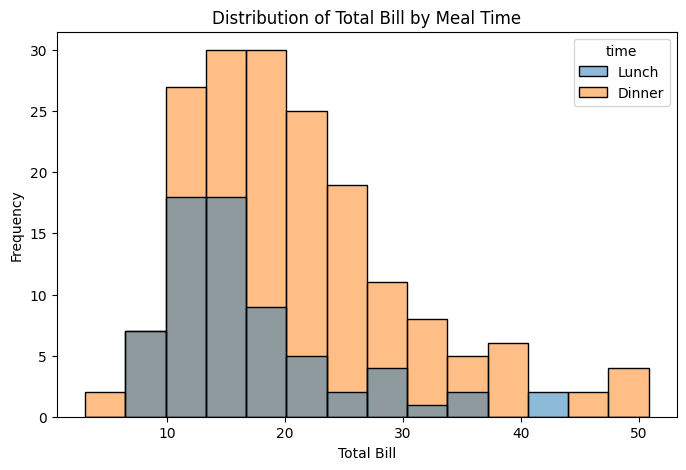

In [2]:

plt.figure(figsize=(8, 5))

sns.histplot(data=tips, x="total_bill", hue="time")

plt.title("Distribution of Total Bill by Meal Time")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")

plt.show()


In [3]:
print(tips.groupby("time")["total_bill"].median())

time
Lunch     15.965
Dinner    18.390
Name: total_bill, dtype: float64


/tmp/ipykernel_464/2059846745.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tips.groupby("time")["total_bill"].median())


# التفسير بعد الرسم

نلاحظ أن فواتير العشاء (Dinner) أعلى من فواتير الغداء (Lunch)، حيث بلغ وسيط الفاتورة للعشاء 18.39، بينما بلغ للغداء 15.965. وهذا يؤكد أن فواتير العشاء تميل إلى أن تكون أعلى.

# الرسم الثاني: توزيع البقشيش حسب اليوم (Boxplot)

**التوقع قبل التشغيل:**

أتوقع أن يختلف وسيط البقشيش من يوم إلى آخر، وأتوقع ظهور قيم شاذة في بعض الأيام.

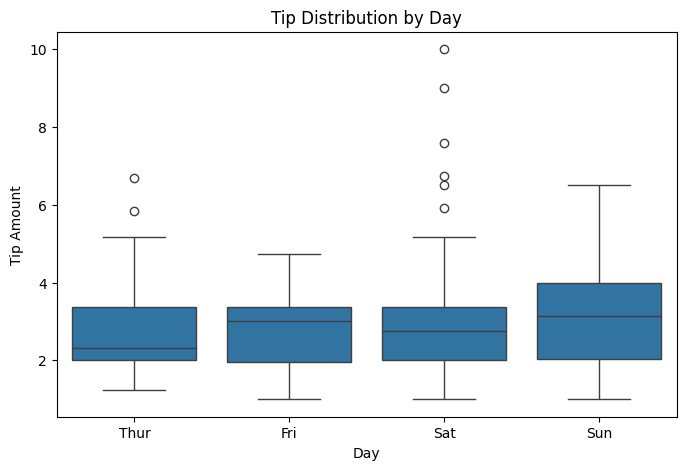

In [4]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=tips, x="day", y="tip")

plt.title("Tip Distribution by Day")
plt.xlabel("Day")
plt.ylabel("Tip Amount")

plt.show()


# التفسير بعد الرسم

نلاحظ أن يوم الأحد لديه أعلى وسيط للبقشيش بقيمة 3.15، بينما يوم السبت لديه أكبر عدد من القيم الشاذة بواقع 6 قيم. وهذا يوضح اختلاف توزيع البقشيش من يوم إلى آخر.

# الرسم الثالث: عدد الفواتير حسب اليوم وحالة التدخين (Countplot)

**التوقع قبل التشغيل:**

أتوقع أن يختلف عدد الفواتير من يوم إلى آخر، وأن يكون عدد فواتير المدخنين وغير المدخنين مختلفًا حسب اليوم.

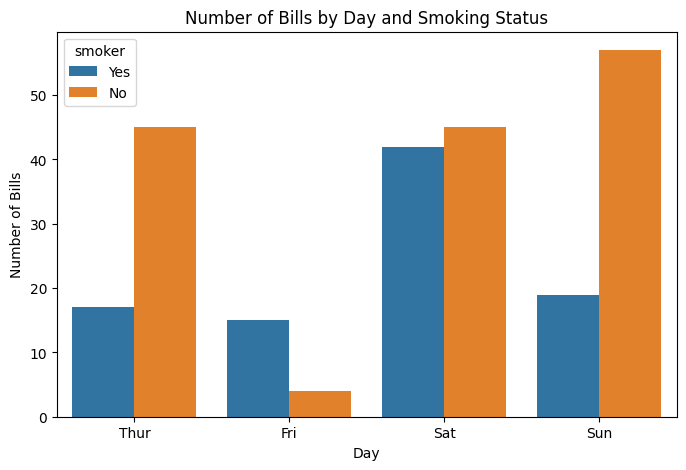

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(data=tips, x="day", hue="smoker")

plt.title("Number of Bills by Day and Smoking Status")
plt.xlabel("Day")
plt.ylabel("Number of Bills")

plt.show()

# التفسير بعد الرسم

نلاحظ أن يوم السبت سجل أعلى عدد من الفواتير بإجمالي 87 فاتورة، يليه الأحد بـ 76 فاتورة، ثم الخميس بـ 62 فاتورة، وأخيرًا الجمعة بـ 19 فاتورة.

كما نلاحظ أن عدد فواتير غير المدخنين كان أعلى من المدخنين في الخميس والسبت والأحد، بينما كان عدد فواتير المدخنين أعلى يوم الجمعة.

 الرسم الرابع: العلاقة بين قيمة الفاتورة والبقشيش (Scatterplot)

**التوقع قبل التشغيل:**

أتوقع وجود علاقة طردية بين قيمة الفاتورة والبقشيش؛ أي كلما زادت قيمة الفاتورة زاد البقشيش غالبًا.

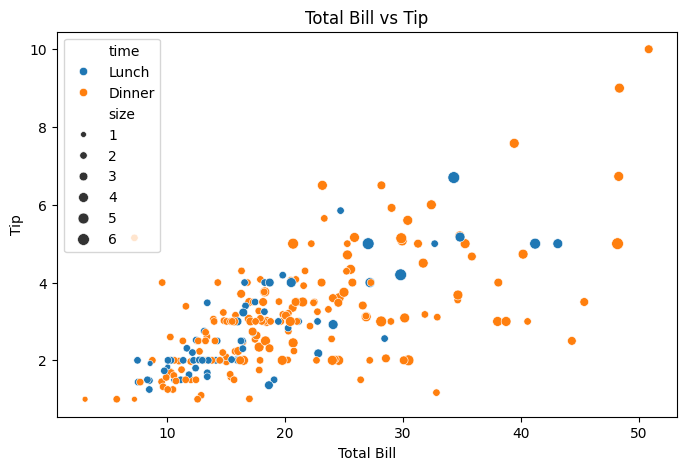

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    size="size"
)

plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")

plt.show()

# التفسير بعد الرسم

نلاحظ وجود علاقة طردية بين قيمة الفاتورة والبقشيش؛ فكلما زادت قيمة الفاتورة زاد البقشيش غالبًا. وقد بلغ معامل الارتباط 0.6757، مما يدل على وجود علاقة طردية متوسطة إلى قوية بين المتغيرين.

# الرسم الخامس: متوسط البقشيش لكل يوم (Barplot)

**التوقع قبل التشغيل:**

أتوقع اختلاف متوسط البقشيش بين أيام الأسبوع، وقد تكون بعض الفروق غير واضحة بسبب تداخل الخطوط السوداء.

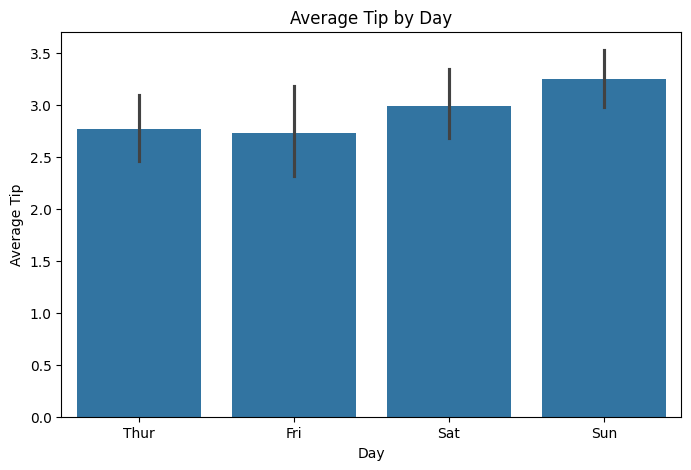

In [10]:
plt.figure(figsize=(8, 5))

sns.barplot(data=tips, x="day", y="tip")

plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip")

plt.show()

**التفسير بعد الرسم:**

نلاحظ أن يوم الأحد لديه أعلى متوسط للبقشيش بقيمة 3.255، يليه السبت بقيمة 2.993، ثم الخميس بقيمة 2.771، وأخيرًا الجمعة بقيمة 2.735.

تظهر الخطوط السوداء فوق الأعمدة لتمثل فترات الثقة، ومن خلالها يمكن ملاحظة مدى عدم اليقين في تقدير المتوسط. ولا يكفي اختلاف ارتفاع الأعمدة وحده للحكم بأن الفرق بين الأيام حقيقي.

 الرسم السادس: مصفوفة الارتباط بين الفاتورة والبقشيش وحجم المجموعة (Heatmap)

**التوقع قبل التشغيل:**

أتوقع وجود علاقة طردية بين قيمة الفاتورة والبقشيش، وقد يكون حجم المجموعة مرتبطًا أيضًا بزيادة قيمة الفاتورة.

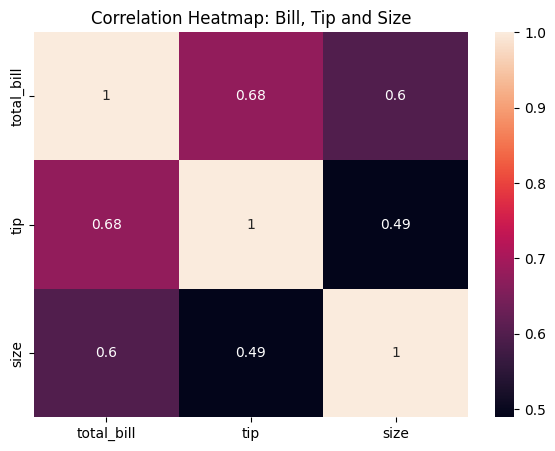

In [12]:
corr = tips[["total_bill", "tip", "size"]].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(corr, annot=True)

plt.title("Correlation Heatmap: Bill, Tip and Size")

plt.show()

التفسير بعد الرسم

نلاحظ وجود علاقة طردية بين المتغيرات الثلاثة.

- أقوى علاقة بين قيمة الفاتورة والبقشيش، حيث بلغ الارتباط 0.676.
- العلاقة بين قيمة الفاتورة وحجم المجموعة بلغت 0.598.
- العلاقة بين البقشيش وحجم المجموعة بلغت 0.489.

هذا يدل على أن زيادة قيمة الفاتورة ترتبط غالبًا بزيادة البقشيش، كما أن حجم المجموعة يرتبط بزيادة قيمة الفاتورة.

 Task 3: تحليل بيانات القروض  

# مقدمة المهمة

في هذه المهمة سنستخدم بيانات القروض التي قمنا بتنظيفها الأسبوع الماضي في ملف loan_clean.csv، ونحوّل أهم الاستنتاجات السابقة إلى رسوم بيانية لفهم طلبات القروض والعوامل المرتبطة بالموافقة عليها.

In [17]:
import pandas as pd

url = "https://raw.githubusercontent.com/Architectshwet/Loan-prediction-using-Machine-Learning-and-Python/master/data/train_u6lujuX_CVtuZ9i.csv"

raw_df = pd.read_csv(url)

print("Shape:", raw_df.shape)
print(raw_df.head())
print("\nMissing values:")
print(raw_df.isnull().sum())

Shape: (614, 13)
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2  

In [18]:
df = raw_df.copy()

# تعويض القيم الناقصة في الأعمدة النصية بالمنوال
for col in ["Gender", "Married", "Self_Employed"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# تحويل 3+ إلى 3 ثم تعويض القيم الناقصة بالوسيط
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(float)
df["Dependents"] = df["Dependents"].fillna(df["Dependents"].median())

# تعويض القيم الناقصة بالمنوال
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].mode()[0])
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].mode()[0])

# وضع -1 للقيم الناقصة في Credit_History
df["Credit_History"] = df["Credit_History"].fillna(-1)

# تحويل قرار القرض إلى أرقام
df["Loan_Status"] = df["Loan_Status"].map({"N": 0, "Y": 1})

# حفظ الملف
df.to_csv("loan_clean.csv", index=False)

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("\nLoan Status counts:")
print(df["Loan_Status"].value_counts())

Shape: (614, 13)
Missing values: 0

Loan Status counts:
Loan_Status
1    422
0    192
Name: count, dtype: int64


In [19]:
df.to_csv("loan_clean.csv", index=False)

print("File saved successfully!")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

File saved successfully!
Shape: (614, 13)
Missing values: 0


 الرسم الأول: عدد طلبات القروض المقبولة والمرفوضة (Countplot)

**التوقع قبل التشغيل:**

أتوقع أن يكون عدد طلبات القروض المقبولة أكبر من عدد الطلبات المرفوضة.

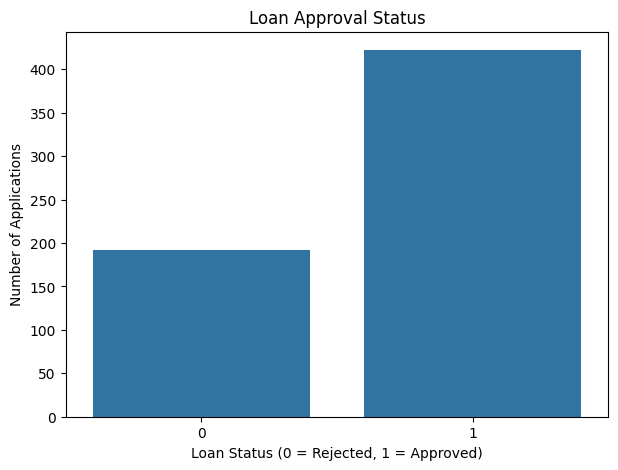

In [20]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Loan_Status")

plt.title("Loan Approval Status")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Number of Applications")

plt.show()

التفسير بعد الرسم

نلاحظ أن عدد طلبات القروض المقبولة بلغ 422 طلبًا، بينما بلغ عدد الطلبات المرفوضة 192 طلبًا. وهذا يؤكد أن الطلبات المقبولة أكثر من الطلبات المرفوضة، بنسبة موافقة بلغت 68.73%.

### الرسم الثاني: نسبة الموافقة حسب التاريخ الائتماني والمنطقة (Barplot)

**التوقع قبل التشغيل:**

أتوقع أن تكون نسبة الموافقة أعلى للمتقدمين الذين لديهم سجل ائتماني جيد، وأن تختلف نسبة الموافقة حسب المنطقة السكنية.

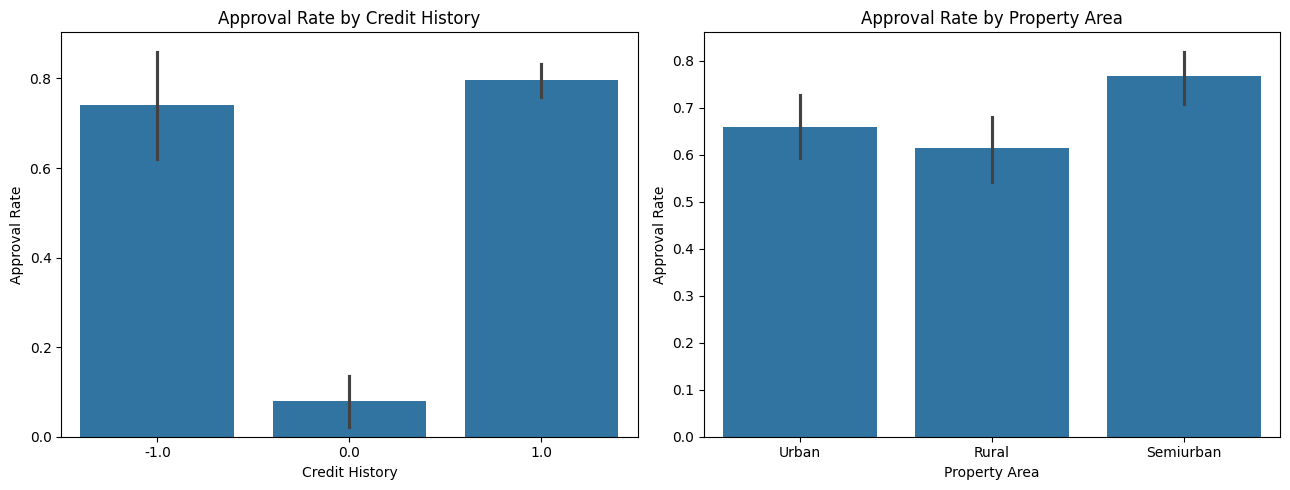

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=df, x="Credit_History", y="Loan_Status", ax=axes[0])
axes[0].set_title("Approval Rate by Credit History")
axes[0].set_xlabel("Credit History")
axes[0].set_ylabel("Approval Rate")

sns.barplot(data=df, x="Property_Area", y="Loan_Status", ax=axes[1])
axes[1].set_title("Approval Rate by Property Area")
axes[1].set_xlabel("Property Area")
axes[1].set_ylabel("Approval Rate")

plt.tight_layout()
plt.show()

التفسير بعد الرسم

نلاحظ أن أعلى نسبة موافقة حسب التاريخ الائتماني كانت للمتقدمين الذين لديهم سجل ائتماني جيد (1)، بنسبة 79.58%، بينما بلغت نسبة الموافقة للمتقدمين ذوي السجل الائتماني (0) حوالي 7.87%.

كما نلاحظ أن منطقة Semiurban سجلت أعلى نسبة موافقة بين المناطق بنسبة 76.82%، تليها Urban بنسبة 65.84%، ثم Rural بنسبة 61.45%.

توضح النتائج أن التاريخ الائتماني والمنطقة السكنية يرتبطان بنسب الموافقة على القروض.

 الرسم الثالث: مقارنة الدخل ومبلغ القرض حسب قرار الموافقة (Boxplot)

التوقع قبل التشغيل

أتوقع أن يختلف توزيع دخل المتقدمين ومبالغ القروض بين الطلبات المقبولة والمرفوضة، لكن قد لا يكون الدخل وحده كافيًا للتمييز بين المجموعتين.

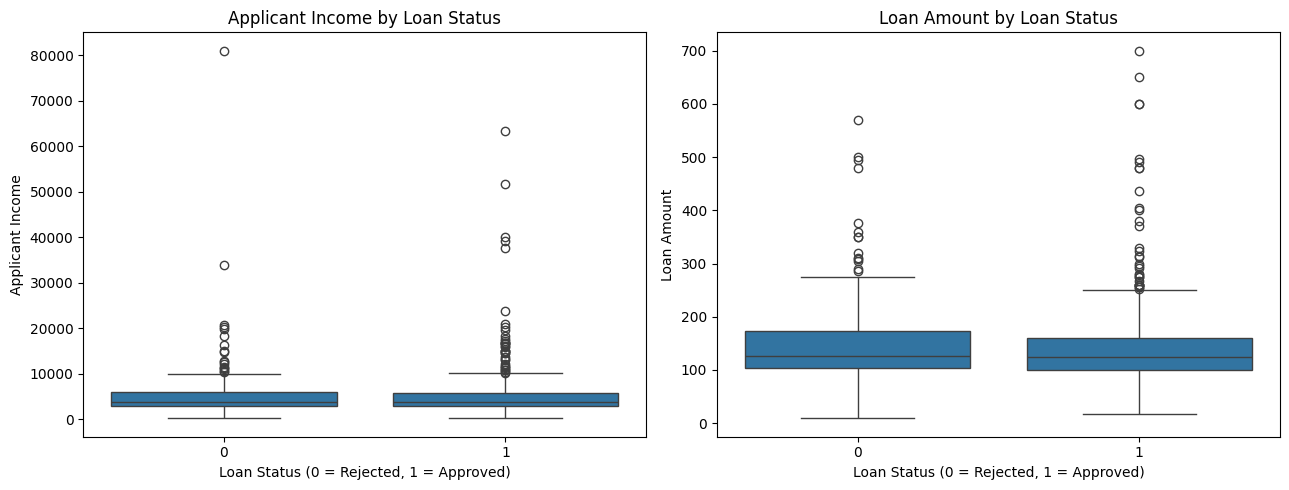

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Loan_Status", y="ApplicantIncome", ax=axes[0])
axes[0].set_title("Applicant Income by Loan Status")
axes[0].set_xlabel("Loan Status (0 = Rejected, 1 = Approved)")
axes[0].set_ylabel("Applicant Income")

sns.boxplot(data=df, x="Loan_Status", y="LoanAmount", ax=axes[1])
axes[1].set_title("Loan Amount by Loan Status")
axes[1].set_xlabel("Loan Status (0 = Rejected, 1 = Approved)")
axes[1].set_ylabel("Loan Amount")

plt.tight_layout()
plt.show()

التفسير بعد الرسم

نلاحظ أن وسيط دخل المتقدمين المرفوضين بلغ 3833.5، بينما بلغ لدى المقبولين 3812.5، وهي قيم متقاربة جدًا.

كما بلغ وسيط مبلغ القرض للطلبات المرفوضة 126.5، وللطلبات المقبولة 125، وهذا يدل على تقارب المجموعتين أيضًا.

من خلال الرسم، نلاحظ أن الدخل ومبلغ القرض وحدهما لا يميزان بشكل واضح بين الطلبات المقبولة والمرفوضة، لذلك نحتاج إلى النظر إلى عوامل أخرى مثل التاريخ الائتماني.

 الرسم الرابع: توزيع دخل المتقدمين (Histplot)

**التوقع قبل التشغيل:**

أتوقع أن تتركز معظم الدخول في القيم المنخفضة والمتوسطة، مع وجود عدد قليل من المتقدمين الذين لديهم دخول مرتفعة جدًا.

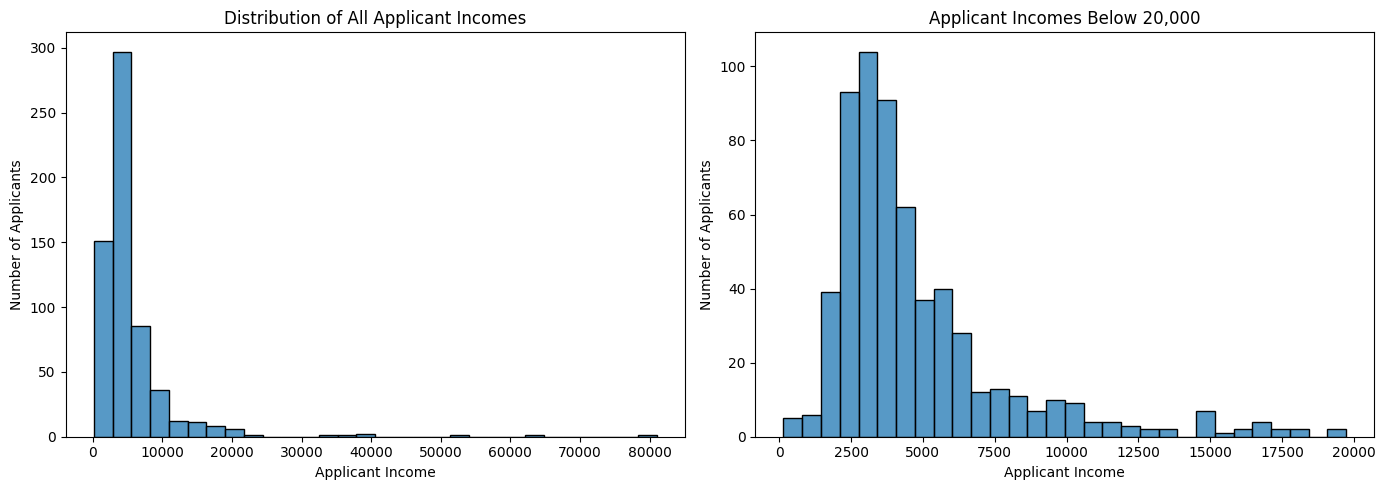

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# الرسم الأول: توزيع جميع الدخول
sns.histplot(data=df, x="ApplicantIncome", bins=30, ax=axes[0])
axes[0].set_title("Distribution of All Applicant Incomes")
axes[0].set_xlabel("Applicant Income")
axes[0].set_ylabel("Number of Applicants")

# الرسم الثاني: توزيع الدخول الأقل من 20,000
filtered_df = df[df["ApplicantIncome"] < 20000]

sns.histplot(data=filtered_df, x="ApplicantIncome", bins=30, ax=axes[1])
axes[1].set_title("Applicant Incomes Below 20,000")
axes[1].set_xlabel("Applicant Income")
axes[1].set_ylabel("Number of Applicants")

plt.tight_layout()
plt.show()

# التفسير بعد الرسم

نلاحظ أن توزيع الدخل في الرسم الأول يظهر بشكل مضغوط بسبب وجود قيم دخل مرتفعة تصل إلى 81,000.

أما الرسم الثاني، الذي يعرض الدخول الأقل من 20,000، فيوضح توزيع معظم المتقدمين بشكل أكبر، حيث يشمل 602 متقدم من أصل 614.

لذلك كان الرسم الثاني أوضح في إظهار تفاصيل توزيع الدخول، لأنه قلل تأثير القيم المرتفعة على مقياس الرسم، دون حذفها من البيانات الأصلية.

 الرسم الخامس: خريطة الارتباط بين الأعمدة الرقمية وقرار الموافقة (Heatmap)

**التوقع قبل التشغيل:**

أتوقع أن يظهر التاريخ الائتماني ارتباطًا أوضح بقرار الموافقة على القرض مقارنةً بالدخل.

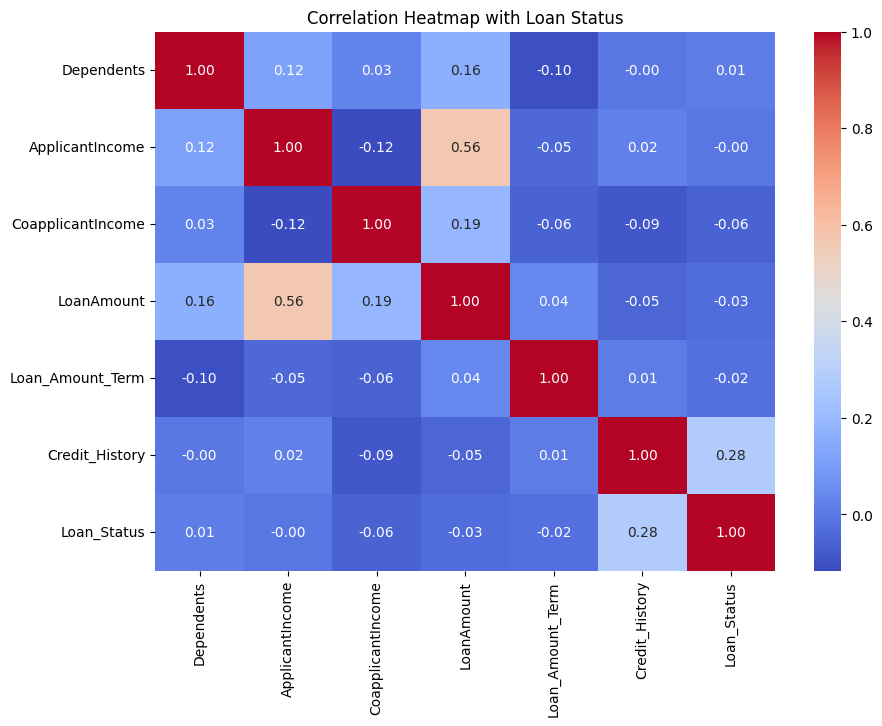

In [28]:
# Select numeric columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Draw heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap with Loan Status")
plt.show()

**التفسير بعد الرسم:**

نلاحظ أن Credit_History حقق أعلى ارتباط مع قرار الموافقة على القرض بقيمة 0.280، وهو ارتباط موجب، مما يعني أن تحسن التاريخ الائتماني يرتبط بزيادة احتمالية الموافقة.

أما الدخل (ApplicantIncome) فكان ارتباطه ضعيفًا جدًا بقيمة -0.005، وكذلك مبلغ القرض (LoanAmount) بقيمة -0.032.

توضح النتائج أن التاريخ الائتماني أكثر ارتباطًا بقرار الموافقة من دخل المتقدم أو مبلغ القرض.

## الاستنتاجات النهائية من الرسوم

### 1. ماذا تقول كل رسمة؟ وما الرقم الذي يؤكدها؟

- **Countplot:** عدد الطلبات المقبولة أكبر من المرفوضة؛ حيث بلغ عدد المقبولة 422 والمرفوضة 192، بنسبة موافقة 68.73%.
- **Barplot:** التاريخ الائتماني والمنطقة السكنية يرتبطان باختلاف نسب الموافقة؛ حيث بلغت نسبة الموافقة لمن لديهم تاريخ ائتماني جيد 79.58%، وسجلت منطقة Semiurban أعلى نسبة موافقة بلغت 76.82%.
- **Boxplot:** الدخل ومبلغ القرض متقاربان بين المقبولين والمرفوضين؛ إذ بلغ وسيط الدخل 3812.5 للمقبولين و3833.5 للمرفوضين.
- **Histplot:** معظم المتقدمين دخلهم أقل من 20,000؛ حيث شمل الرسم الثاني 602 متقدم من أصل 614، وأظهر توزيع الدخول بوضوح أكبر.
- **Heatmap:** التاريخ الائتماني هو الأعلى ارتباطًا بقرار الموافقة بقيمة 0.280، بينما كان ارتباط الدخل -0.005.

### 2. أي استنتاج من الأسبوع الماضي أصبح أوضح بالرسوم؟

أصبح واضحًا أن التاريخ الائتماني من أهم العوامل المرتبطة بالموافقة على القروض، وأن الدخل وحده لا يوضح الفرق بين الطلبات المقبولة والمرفوضة.

### 3. هل كشفت الرسوم شيئًا لم ألاحظه بالأرقام؟

نعم، أوضحت الرسوم شكل توزيع الدخول ووجود قيم مرتفعة جدًا تؤثر على مقياس الرسم، كما أظهر Boxplot تقارب توزيع الدخل ومبالغ القروض بين المجموعتين، وهذا يصعب ملاحظته من الأرقام وحدها.

# Task 4: Dragon Records 🐉

في هذه المهمة سأحلل بيانات 150 تنينًا من ثلاثة أنواع: Fire وIce وStorm. سأكتشف الأخطاء في البيانات وأصححها، ثم أستخدم الرسوم البيانية لتحليل خصائص التنانين واختيار النوع الأنسب لتدفئة القرية.

In [45]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
n = 150

species = rng.choice(
    ["Fire", "Ice", "Storm"],
    n,
    p=[0.4, 0.35, 0.25]
)

base_wing = {"Fire": 14, "Ice": 11, "Storm": 18}
base_heat = {"Fire": 900, "Ice": 80, "Storm": 300}

dragons = pd.DataFrame({
    "dragon_id": [f"D{i:03d}" for i in range(n)],
    "species": species,
    "wingspan_m": [
        round(base_wing[s] + rng.normal(0, 2), 1)
        for s in species
    ],
    "fire_temp_c": [
        round(base_heat[s] + rng.normal(0, 60))
        for s in species
    ],
    "age_years": rng.integers(20, 400, n),
})

dragons["weight_t"] = (
    dragons["wingspan_m"] * 0.6 + rng.normal(0, 0.8, n)
).round(1)

dragons.loc[37, "wingspan_m"] = 140.0

print("Dataset Shape:", dragons.shape)
print(dragons.head())

Dataset Shape: (150, 6)
  dragon_id species  wingspan_m  fire_temp_c  age_years  weight_t
0      D000     Ice        11.0           83         58       6.1
1      D001   Storm        16.6          391        232       9.4
2      D002   Storm        17.3          333        130      10.3
3      D003    Fire        12.9          896        170       6.9
4      D004    Fire        14.0          865         83       8.9


### الرسم الأول: عدد التنانين من كل نوع (Countplot)

يهدف هذا الرسم إلى معرفة عدد التنانين الموجودة من كل نوع، ومقارنة توزيع الأنواع الثلاثة.

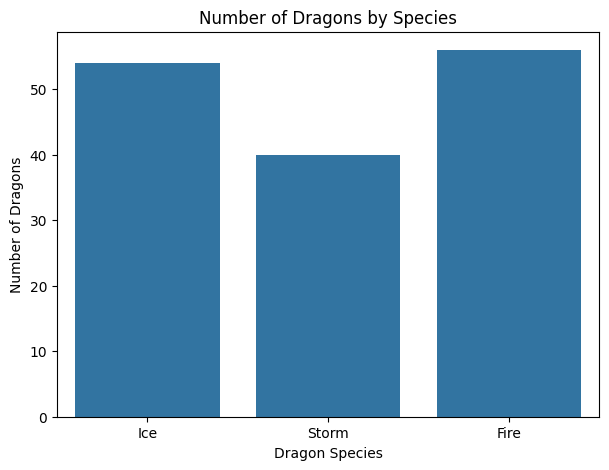

In [46]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=dragons,
    x="species"
)

plt.title("Number of Dragons by Species")
plt.xlabel("Dragon Species")
plt.ylabel("Number of Dragons")
plt.show()

**التفسير بعد الرسم:**

نلاحظ أن نوع Fire هو الأكثر عددًا بواقع 56 تنينًا، يليه نوع Ice بعدد 54 تنينًا، ثم نوع Storm بعدد 40 تنينًا.

وهذا يوضح أن Fire هو النوع الأكثر انتشارًا في السجل، بينما Storm هو الأقل عددًا.

### اكتشاف الخطأ وتصحيحه

**التوقع قبل الفحص:**

أتوقع وجود قيمة غير طبيعية في عمود طول الجناح (`wingspan_m`)، وقد تكون ناتجة عن خطأ في إدخال البيانات.

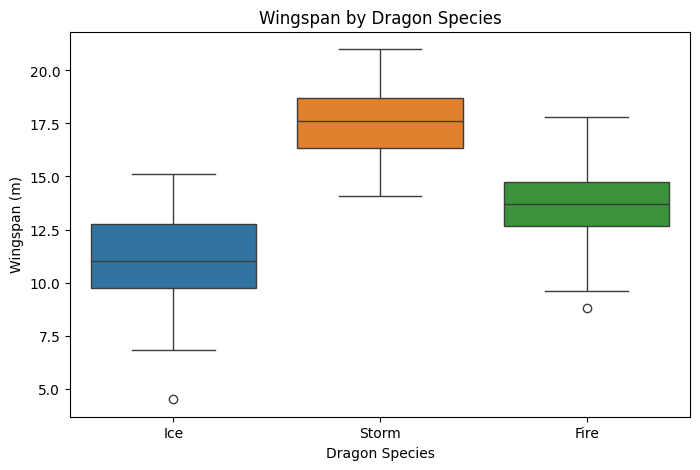

In [55]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=dragons,
    x="species",
    y="wingspan_m",
    hue="species"
)

plt.title("Wingspan by Dragon Species")
plt.xlabel("Dragon Species")
plt.ylabel("Wingspan (m)")
plt.show()

In [48]:
print(
    dragons.nlargest(5, "wingspan_m")[
        ["dragon_id", "species", "wingspan_m"]
    ]
)

    dragon_id species  wingspan_m
37       D037    Fire       140.0
56       D056   Storm        21.0
27       D027   Storm        20.7
43       D043   Storm        19.9
143      D143   Storm        19.9


**ملاحظة:**

وجدت أن التنين D037 لديه طول جناح يبلغ 140 مترًا، وهي قيمة غير طبيعية مقارنة ببقية التنانين. أعتقد أن السبب قد يكون خطأ في إدخال البيانات، مثل إضافة صفر بالخطأ.

سأستخدم وسيط أطوال أجنحة تنانين Fire لتصحيح القيمة؛ لأن الوسيط أقل تأثرًا بالقيم المتطرفة.

In [49]:
fire_median = dragons.loc[
    (dragons["species"] == "Fire") &
    (dragons["dragon_id"] != "D037"),
    "wingspan_m"
].median()

print("Median wingspan for Fire dragons:", fire_median)

Median wingspan for Fire dragons: 13.7


In [50]:
dragons.loc[
    dragons["dragon_id"] == "D037",
    "wingspan_m"
] = fire_median

print(
    dragons.loc[
        dragons["dragon_id"] == "D037",
        ["dragon_id", "species", "wingspan_m"]
    ]
)

   dragon_id species  wingspan_m
37      D037    Fire        13.7


**التفسير بعد الفحص والتصحيح:**

اكتشفت وجود قيمة غير طبيعية في سجل التنين D037 من نوع Fire، حيث كان طول جناحه 140 مترًا، وهي قيمة بعيدة جدًا عن بقية أطوال الأجنحة.

أعتقد أن السبب هو خطأ في إدخال البيانات، مثل إضافة صفر بالخطأ.

صححت القيمة باستخدام الوسيط (Median) لأطوال أجنحة تنانين Fire، وكانت القيمة 13.7 مترًا. اخترت الوسيط لأنه أقل تأثرًا بالقيم المتطرفة ويساعد على إعطاء قيمة مناسبة لهذا النوع.

### الرسم الثاني: Boxplot لطول الجناح مقابل حرارة النار حسب النوع

**التوقع قبل الرسم:**

أتوقع أن تختلف أطوال الأجنحة باختلاف درجات حرارة النار وأن يظهر نوع التنين في مجموعات مختلفة حسب درجة حرارته.

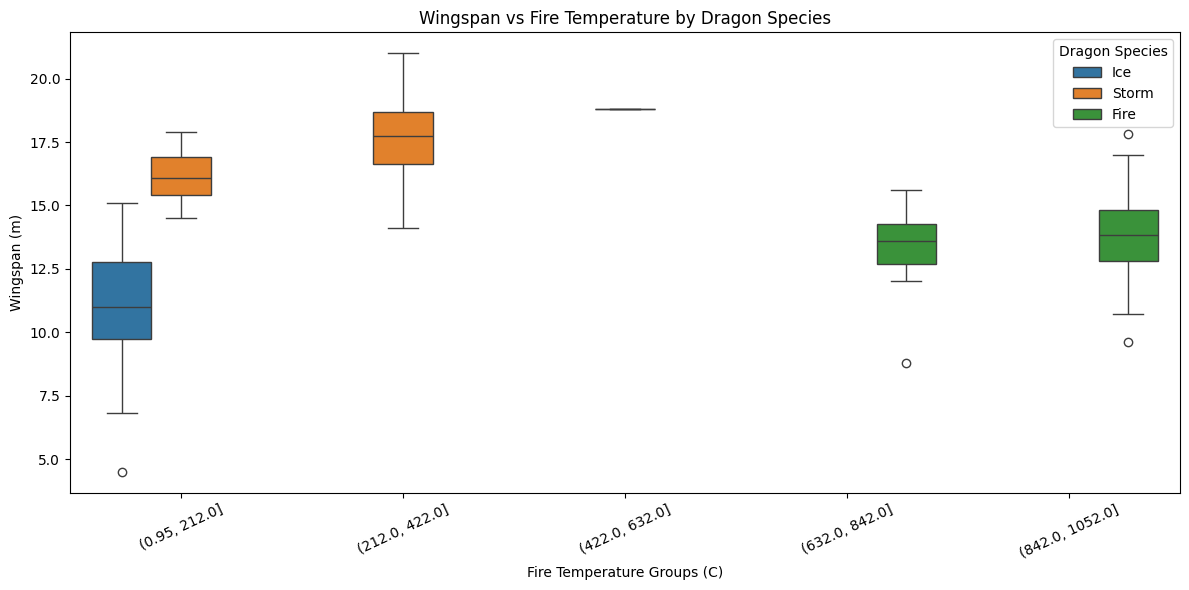

In [51]:
# تقسيم درجات حرارة النار إلى مجموعات
dragons["heat_group"] = pd.cut(
    dragons["fire_temp_c"],
    bins=5
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=dragons,
    x="heat_group",
    y="wingspan_m",
    hue="species"
)

plt.title("Wingspan vs Fire Temperature by Dragon Species")
plt.xlabel("Fire Temperature Groups (C)")
plt.ylabel("Wingspan (m)")
plt.xticks(rotation=25)
plt.legend(title="Dragon Species")
plt.tight_layout()
plt.show()

**التفسير بعد الرسم:**

يوضح الرسم توزيع أطوال أجنحة التنانين حسب مجموعات حرارة النار والأنواع المختلفة.

نلاحظ أن تنانين Ice تظهر في مجموعات درجات الحرارة المنخفضة، بينما تظهر تنانين Storm في درجات الحرارة المتوسطة، وتنانين Fire في مجموعات درجات الحرارة المرتفعة.

كما نلاحظ اختلاف أطوال الأجنحة بين الأنواع، حيث تتميز تنانين Storm بأطول أجنحة مقارنةً ببقية الأنواع.

### الرسم الثالث: Scatterplot للعلاقة بين طول الجناح والوزن

يهدف الرسم إلى دراسة العلاقة بين طول جناح التنين ووزنه، ومعرفة مدى قوة الارتباط بينهما.

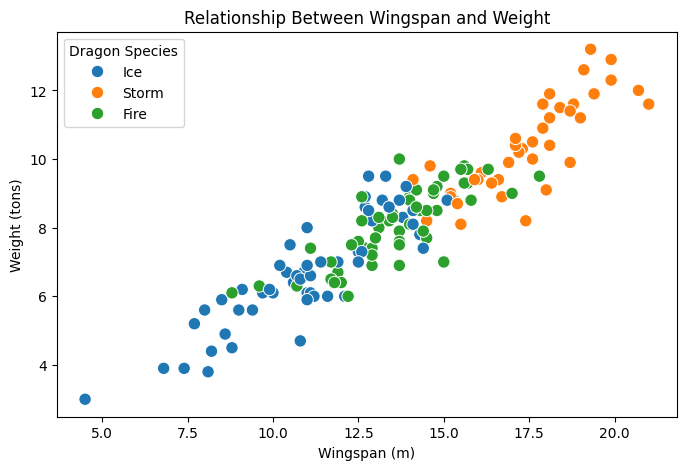

In [52]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=dragons,
    x="wingspan_m",
    y="weight_t",
    hue="species",
    s=80
)

plt.title("Relationship Between Wingspan and Weight")
plt.xlabel("Wingspan (m)")
plt.ylabel("Weight (tons)")
plt.legend(title="Dragon Species")
plt.show()

**التفسير بعد الرسم:**

يوضح الرسم وجود علاقة طردية قوية جدًا بين طول الجناح ووزن التنين.

بلغ معامل الارتباط بين `wingspan_m` و`weight_t` حوالي 0.9277، وهي قيمة قريبة من 1، مما يدل على ارتباط قوي جدًا بين العمودين.

لذلك أستنتج أن طول الجناح والوزن يكادان يقيسان الشيء نفسه في هذه البيانات؛ لأن زيادة طول الجناح ترتبط غالبًا بزيادة وزن التنين.

### الرسم الرابع: خريطة الارتباط (Heatmap)

تساعد خريطة الارتباط على معرفة قوة واتجاه العلاقة بين الأعمدة الرقمية في بيانات التنانين، وتحديد الأعمدة الأكثر ارتباطًا ببعضها.

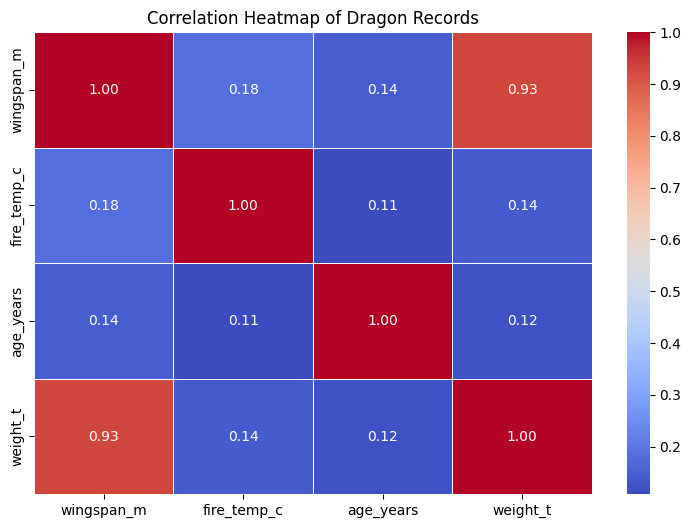

In [54]:
plt.figure(figsize=(9, 6))

numeric_data = dragons.select_dtypes(include="number")

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Dragon Records")
plt.show()

**التفسير بعد الرسم:**

توضح خريطة الارتباط وجود علاقة طردية قوية بين طول الجناح والوزن، مما يدل على أن زيادة طول الجناح ترتبط غالبًا بزيادة وزن التنين.

كما تساعد الخريطة على معرفة العلاقات بين الأعمدة الرقمية، وتحديد الأعمدة التي تحمل معلومات متشابهة.

## القرار النهائي: اختيار التنانين لتدفئة القرية

**1. النوع الذي سأرسله: Fire 🔥**

سأرسل تنانين Fire لتدفئة القرية؛ لأنها تمتلك أعلى متوسط لحرارة النار، حيث بلغ 893.54 درجة مئوية. ويؤكد الرسم أن درجات حرارة هذا النوع هي الأعلى.

**2. النوع الذي لن أرسله أبدًا: Ice ❄️**

لن أرسل تنانين Ice؛ لأنها تمتلك أقل متوسط لحرارة النار، حيث بلغ 79.19 درجة مئوية فقط. ويوضح الرسم أنها الأقل قدرة على إنتاج الحرارة.

**النتيجة:**

أختار Fire لتدفئة القرية، وأستبعد Ice، اعتمادًا على الرسم ومتوسط درجات الحرارة.